This notebook is used for plotting figures only. 

In [17]:
%matplotlib inline

from __future__ import annotations

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# __file__ only exists in .py scripts, not in Jupyter notebooks
PROJECT_ROOT = Path.cwd()
RESULTS_DIR = PROJECT_ROOT / "results"

# Results with warm start point

In [27]:
NN_HISTORY_PATH = RESULTS_DIR / "NN_solver_history_20260826-145443.csv"
TR_HISTORY_PATH = RESULTS_DIR / "trust_region_history_20260827-045527.csv"
TR_RESULT_PATH = RESULTS_DIR / "trust_region_result_20260827-045527.json"
ZERO_RESULT_PATH = RESULTS_DIR / "zero_solver_result_20260826-213110.json"
ZERO_HISTORY_PATH = RESULTS_DIR / "zero_solver_history_20260826-213110.csv"
ZERO_SOLUTION_PATH = RESULTS_DIR / "zero_solver_solution_20260826-213110.csv"

scenarios = ["SB", "SB", "BG", "BG", "IP",]
T = 24

nn_history = pd.read_csv(NN_HISTORY_PATH)
last_nn_row = nn_history.sort_values("iteration").iloc[-1]
pi_columns = sorted(
        (column for column in nn_history.columns if column.startswith("pi_")),
        key=lambda column: int(column.removeprefix("pi_")),
    )
nn_prices = last_nn_row[pi_columns].to_numpy(dtype=float).reshape(
        len(scenarios), T
    ) 
print(f"Loaded NN solution: shape={nn_prices.shape}")

tr_history_ws = pd.read_csv(TR_HISTORY_PATH)
with TR_RESULT_PATH.open("r", encoding="utf-8") as file:
    tr_result_ws = json.load(file)
print(f"Loaded TR history: {TR_HISTORY_PATH.name}  shape={tr_history_ws.shape}")
print(f"Loaded TR result:  {TR_RESULT_PATH.name}  n_iter={tr_result_ws.get('n_iter')}  converged={tr_result_ws.get('converged')}")

with ZERO_RESULT_PATH.open("r", encoding="utf-8") as file:
    zero_result_ws = json.load(file)
zero_history_ws = pd.read_csv(ZERO_HISTORY_PATH)
zero_solution_ws = pd.read_csv(ZERO_SOLUTION_PATH)
print(f"Loaded CMA result: {ZERO_RESULT_PATH.name}  optimal_value={zero_result_ws['optimal_value']:.4f}")
print(f"Loaded CMA history: {ZERO_HISTORY_PATH.name}  shape={zero_history_ws.shape}")
print(f"Loaded CMA solution: {ZERO_SOLUTION_PATH.name}  shape={zero_solution_ws.shape}")


Loaded NN solution: shape=(5, 24)
Loaded TR history: trust_region_history_20260827-045527.csv  shape=(48, 12)
Loaded TR result:  trust_region_result_20260827-045527.json  n_iter=48  converged=True
Loaded CMA result: zero_solver_result_20260826-213110.json  optimal_value=-103.2878
Loaded CMA history: zero_solver_history_20260826-213110.csv  shape=(9000, 2)
Loaded CMA solution: zero_solver_solution_20260826-213110.csv  shape=(24, 11)


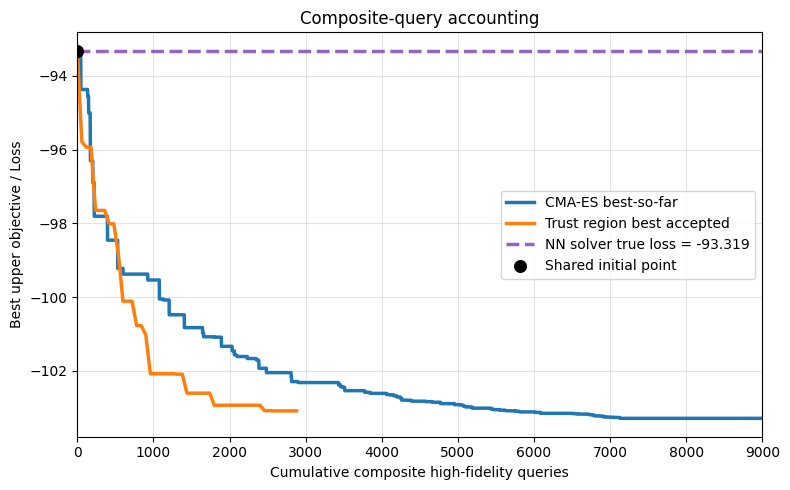

In [28]:
# Compare methods using composite high-fidelity query accounting.
# CMA-ES n_interactions is the number of composite full-price queries.
plt.close("all")

tr_config_n_samples = int(
    tr_result_ws.get("params", {}).get("algo_params", {}).get("n_samples", 60)
)

zero_plot_df = zero_history_ws.copy().sort_values("interaction").reset_index(drop=True)

tr_plot_df = tr_history_ws.copy()
tr_plot_df["accepted"] = tr_plot_df["decision"].astype(str).str.startswith("accept")
tr_plot_df["cumulative_composite_queries"] = (
    (tr_plot_df["k"] + 1) * tr_config_n_samples
)

# The trust-region run evaluates x0 exactly, so use it as the common starting value.
common_initial_objective = float(tr_plot_df.iloc[0]["F_current"])

zero_plot_df = pd.concat(
    [
        pd.DataFrame(
            {
                "interaction": [0],
                "upper_objective": [common_initial_objective],
            }
        ),
        zero_plot_df[["interaction", "upper_objective"]],
    ],
    ignore_index=True,
)
zero_plot_df["best_so_far_loss"] = zero_plot_df["upper_objective"].cummin()

best_accepted = common_initial_objective
tr_best_values = []
for _, row in tr_plot_df.iterrows():
    if row["accepted"]:
        best_accepted = min(best_accepted, float(row["F_candidate"]))
    tr_best_values.append(best_accepted)
tr_plot_df["best_true_objective"] = tr_best_values
tr_plot_df = pd.concat(
    [
        pd.DataFrame(
            {
                "cumulative_composite_queries": [0],
                "best_true_objective": [common_initial_objective],
            }
        ),
        tr_plot_df[["cumulative_composite_queries", "best_true_objective"]],
    ],
    ignore_index=True,
)

nn_true_loss = float(nn_history.sort_values("iteration").iloc[-1]["true_loss"])

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    zero_plot_df["interaction"],
    zero_plot_df["best_so_far_loss"],
    linewidth=2.5,
    label="CMA-ES best-so-far",
)
ax.plot(
    tr_plot_df["cumulative_composite_queries"],
    tr_plot_df["best_true_objective"],
    linewidth=2.5,
    label="Trust region best accepted",
)
ax.axhline(
    nn_true_loss,
    color="tab:purple",
    linestyle="--",
    linewidth=2.5,
    label=f"NN solver true loss = {nn_true_loss:.3f}",
)
ax.scatter(
    [0],
    [common_initial_objective],
    color="black",
    s=70,
    zorder=5,
    label="Shared initial point",
)
x_max = max(
    int(zero_plot_df["interaction"].max()),
    int(tr_plot_df["cumulative_composite_queries"].max()),
)
ax.set_xlim(0, x_max)
ax.set_xlabel("Cumulative composite high-fidelity queries")
ax.set_ylabel("Best upper objective / Loss")
ax.set_title("Composite-query accounting")
ax.grid(alpha=0.35)
ax.legend()
fig.tight_layout()
fig.savefig("plots/Warm_start_query_accounting.pdf", format="pdf", bbox_inches="tight")



In [21]:
# True solutions and true objectives for the three methods.
nn_true_obj = float(nn_history.sort_values("iteration").iloc[-1]["true_loss"])
zero_prices = np.asarray(zero_result_ws["optimal_pi"], dtype=float).reshape(
    len(scenarios), T
)
zero_true_obj = float(zero_result_ws["optimal_value"])

tr_prices = np.asarray(tr_result_ws["x_opt"], dtype=float).reshape(len(scenarios), T)
last_tr_row = tr_history_ws.iloc[-1]
tr_true_obj = (
    float(last_tr_row["F_current"])
    if str(last_tr_row["decision"]) == "reject"
    else float(last_tr_row["F_candidate"])
)

objectives = pd.DataFrame(
    [
        {"method": "NN solver", "true_objective": nn_true_obj},
        {"method": "CMA-ES", "true_objective": zero_true_obj},
        {"method": "Trust region", "true_objective": tr_true_obj},
    ]
).set_index("method")

print("True objectives")
display(objectives)

print("True solutions (prices)")
display(
    pd.concat(
        {
            "NN solver": pd.DataFrame(nn_prices, index=scenarios),
            "CMA-ES": pd.DataFrame(zero_prices, index=scenarios),
            "Trust region": pd.DataFrame(tr_prices, index=scenarios),
        },
        names=["method", "scenario"],
    )
)

True objectives


,true_objective
method,
NN solver,-93.319467
CMA-ES,-103.287808
Trust region,-103.070985


True solutions (prices)


0         1         2         3         4   \
method       scenario                                                     
NN solver    SB        1.484079  0.973433  1.112062  1.131718  1.463976   
             SB        1.486234  0.975952  1.111579  1.136286  1.369770   
             BG        1.497301  1.498154  1.498504  1.498495  1.499143   
             BG        1.497234  1.497965  1.498485  1.496497  1.498889   
             IP        1.364882  1.417841  1.443700  1.425717  1.468716   
CMA-ES       SB        1.496667  0.996915  0.998508  0.941842  1.168387   
             SB        1.497034  0.931306  0.925129  0.887403  1.266973   
             BG        1.485843  1.442288  1.491793  1.499596  1.469064   
             BG        1.482236  1.497783  1.473648  1.499956  1.454572   
             IP        1.499769  1.498503  1.499649  1.499368  1.499502   
Trust region SB        1.016069  1.008214  1.026588  1.007216  1.201799   
             SB        1.000544  1.014585  0.996223  1.029872  1.018476   
             BG        1.499984  1.499983  1.499985  1.499985  1.499983   
             BG        1.499986  1.499985  1.499988  1.499987  1.499985   
             IP        1.492479  1.461188  1.496004  1.485050  1.488791   

                             5         6         7         8         9   ...  \
method       scenario                                                    ...   
NN solver    SB        1.142152  0.984954  0.990144  1.011270  1.239108  ...   
             SB        1.141329  0.960931  0.990486  1.012196  1.251371  ...   
             BG        1.499052  1.498631  1.498759  1.498521  1.498788  ...   
             BG        1.499000  1.498591  1.498955  1.498661  1.498614  ...   
             IP        1.426387  1.457809  1.471633  1.464095  1.474013  ...   
CMA-ES       SB        0.980239  0.972355  1.013324  0.973213  1.207287  ...   
             SB        1.166013  0.960027  0.814288  0.934302  0.986272  ...   
             BG        1.485120  1.475547  1.495328  1.476750  1.493285  ...   
             BG        1.196616  1.486329  1.407120  1.492839  1.495064  ...   
             IP        1.497741  1.499637  1.498845  1.498342  1.499612  ...   
Trust region SB        1.003210  1.039470  1.028728  1.016421  1.000001  ...   
             SB        0.974753  1.030920  1.026056  0.999893  0.984512  ...   
             BG        1.499984  1.499983  1.499983  1.499983  1.499982  ...   
             BG        1.499985  1.499985  1.499985  1.499984  1.499985  ...   
             IP        1.463810  1.485588  1.474991  1.483384  1.499280  ...   

                             14        15        16        17        18  \
method       scenario                                                     
NN solver    SB        1.244825  1.235749  1.461429  1.362108  1.449999   
             SB        1.018656  1.235449  1.411770  1.361089  1.455683   
             BG        1.498941  1.498911  1.499134  1.498889  1.498441   
             BG        1.498912  1.498472  1.499267  1.498871  1.498758   
             IP        1.474267  1.480859  1.469898  1.448282  1.422391   
CMA-ES       SB        1.019375  1.311931  1.357609  1.291369  1.321334   
             SB        1.003027  1.096588  1.314060  1.416474  1.416837   
             BG        1.473741  1.499035  1.482974  1.478454  1.373867   
             BG        1.494577  1.496927  1.498554  1.403735  1.480709   
             IP        1.499981  1.499652  1.499741  1.498615  1.498719   
Trust region SB        1.060895  1.037914  1.490012  1.499983  1.492780   
             SB        1.025702  1.038191  1.466243  1.498251  1.499985   
             BG        1.499983  1.499983  1.499982  1.499983  1.499985   
             BG        1.499983  1.499983  1.499985  1.499984  1.499987   
             IP        1.499741  1.493470  1.499360  1.479939  1.485307   

                             19        20        21        22        23  
method       scenario                     

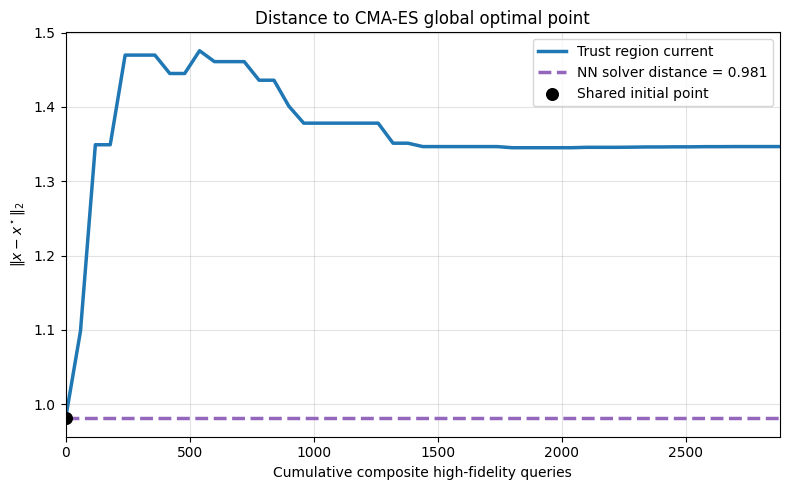

In [22]:
# Distance of the current solution to the CMA-ES final solution (treated as
# the global optimal point) vs composite high-fidelity queries.
# CMA-ES history only stores objectives, not iterates, so it cannot be
# plotted as a trajectory. NN has no queries, so it is a horizontal line.
plt.close("all")

x_star = np.asarray(zero_result_ws["optimal_pi"], dtype=float).reshape(-1)

tr_config_n_samples = int(
    tr_result_ws.get("params", {}).get("algo_params", {}).get("n_samples", 60)
)


def solution_distance(x) -> float:
    return float(np.linalg.norm(np.asarray(x, dtype=float).reshape(-1) - x_star))


tr_hist = tr_result_ws["history"]
tr_queries = [0]
tr_distances = [solution_distance(tr_hist[0]["x_k"])]
for record in tr_hist:
    tr_queries.append(int(record["k"] + 1) * tr_config_n_samples)
    tr_distances.append(solution_distance(record["x_next"]))

nn_distance = solution_distance(nn_prices)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    tr_queries,
    tr_distances,
    linewidth=2.5,
    label="Trust region current",
)
ax.axhline(
    nn_distance,
    color="tab:purple",
    linestyle="--",
    linewidth=2.5,
    label=f"NN solver distance = {nn_distance:.3f}",
)
ax.scatter(
    [0],
    [tr_distances[0]],
    color="black",
    s=70,
    zorder=5,
    label="Shared initial point",
)
ax.set_xlim(0, max(tr_queries))
ax.set_xlabel("Cumulative composite high-fidelity queries")
ax.set_ylabel(r"$\|x - x^\star\|_2$")
ax.set_title("Distance to CMA-ES global optimal point")
ax.grid(alpha=0.35)
ax.legend()
fig.tight_layout()


# Results without warm start point

In [25]:
NN_HISTORY_PATH = RESULTS_DIR / "NN_solver_history_20260826-145443.csv"
TR_HISTORY_PATH = RESULTS_DIR / "trust_region_history_20260828-045534.csv"
TR_RESULT_PATH = RESULTS_DIR / "trust_region_result_20260828-045534.json"
ZERO_RESULT_PATH = RESULTS_DIR / "zero_solver_result_20260827-220057.json"
ZERO_HISTORY_PATH = RESULTS_DIR / "zero_solver_history_20260827-220057.csv"
ZERO_SOLUTION_PATH = RESULTS_DIR / "zero_solver_solution_20260827-220057.csv"

scenarios = ["SB", "SB", "BG", "BG", "IP",]
T = 24

nn_history = pd.read_csv(NN_HISTORY_PATH)
last_nn_row = nn_history.sort_values("iteration").iloc[-1]
pi_columns = sorted(
        (column for column in nn_history.columns if column.startswith("pi_")),
        key=lambda column: int(column.removeprefix("pi_")),
    )
nn_prices = last_nn_row[pi_columns].to_numpy(dtype=float).reshape(
        len(scenarios), T
    ) 
print(f"Loaded NN solution: shape={nn_prices.shape}")

tr_history_cs = pd.read_csv(TR_HISTORY_PATH)
with TR_RESULT_PATH.open("r", encoding="utf-8") as file:
    tr_result_cs = json.load(file)
print(f"Loaded TR history: {TR_HISTORY_PATH.name}  shape={tr_history_cs.shape}")
print(f"Loaded TR result:  {TR_RESULT_PATH.name}  n_iter={tr_result_cs.get('n_iter')}  converged={tr_result_cs.get('converged')}")

with ZERO_RESULT_PATH.open("r", encoding="utf-8") as file:
    zero_result_cs = json.load(file)
zero_history_cs = pd.read_csv(ZERO_HISTORY_PATH)
zero_solution_cs = pd.read_csv(ZERO_SOLUTION_PATH)
print(f"Loaded CMA result: {ZERO_RESULT_PATH.name}  optimal_value={zero_result_cs['optimal_value']:.4f}")
print(f"Loaded CMA history: {ZERO_HISTORY_PATH.name}  shape={zero_history_cs.shape}")
print(f"Loaded CMA solution: {ZERO_SOLUTION_PATH.name}  shape={zero_solution_cs.shape}")


Loaded NN solution: shape=(5, 24)
Loaded TR history: trust_region_history_20260828-045534.csv  shape=(43, 12)
Loaded TR result:  trust_region_result_20260828-045534.json  n_iter=43  converged=True
Loaded CMA result: zero_solver_result_20260827-220057.json  optimal_value=-89.3682
Loaded CMA history: zero_solver_history_20260827-220057.csv  shape=(16290, 2)
Loaded CMA solution: zero_solver_solution_20260827-220057.csv  shape=(24, 11)


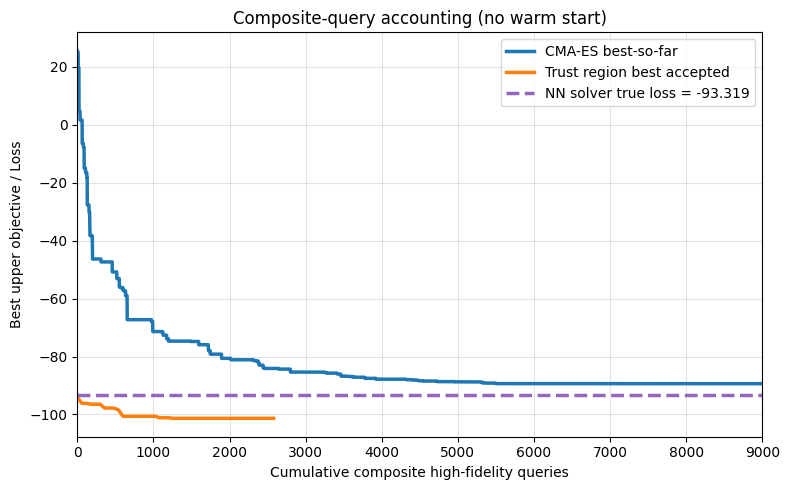

In [30]:
# Compare methods using composite high-fidelity query accounting (no warm start).
# CMA-ES n_interactions is the number of composite full-price queries.
plt.close("all")

tr_config_n_samples = int(
    tr_result_cs.get("params", {}).get("algo_params", {}).get("n_samples", 60)
)

zero_plot_df = zero_history_cs.copy().sort_values("interaction").reset_index(drop=True)
zero_plot_df["best_so_far_loss"] = zero_plot_df["upper_objective"].cummin()

tr_plot_df = tr_history_cs.copy()
tr_plot_df["accepted"] = tr_plot_df["decision"].astype(str).str.startswith("accept")
tr_plot_df["cumulative_composite_queries"] = (
    (tr_plot_df["k"] + 1) * tr_config_n_samples
)

tr_initial_objective = float(tr_plot_df.iloc[0]["F_current"])
best_accepted = tr_initial_objective
tr_best_values = []
for _, row in tr_plot_df.iterrows():
    if row["accepted"]:
        best_accepted = min(best_accepted, float(row["F_candidate"]))
    tr_best_values.append(best_accepted)
tr_plot_df["best_true_objective"] = tr_best_values
tr_plot_df = pd.concat(
    [
        pd.DataFrame(
            {
                "cumulative_composite_queries": [0],
                "best_true_objective": [tr_initial_objective],
            }
        ),
        tr_plot_df[["cumulative_composite_queries", "best_true_objective"]],
    ],
    ignore_index=True,
)

nn_true_loss = float(nn_history.sort_values("iteration").iloc[-1]["true_loss"])

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    zero_plot_df["interaction"],
    zero_plot_df["best_so_far_loss"],
    linewidth=2.5,
    label="CMA-ES best-so-far",
)
ax.plot(
    tr_plot_df["cumulative_composite_queries"],
    tr_plot_df["best_true_objective"],
    linewidth=2.5,
    label="Trust region best accepted",
)
ax.axhline(
    nn_true_loss,
    color="tab:purple",
    linestyle="--",
    linewidth=2.5,
    label=f"NN solver true loss = {nn_true_loss:.3f}",
)
# ax.scatter(
#     [0],
#     [tr_initial_objective],
#     color="black",
#     s=70,
#     zorder=5,
#     label="TR initial point",
# )
ax.set_xlim(0, 9000)
ax.set_xlabel("Cumulative composite high-fidelity queries")
ax.set_ylabel("Best upper objective / Loss")
ax.set_title("Composite-query accounting (no warm start)")
ax.grid(alpha=0.35)
ax.legend()
fig.tight_layout()
fig.savefig("plots/Cold_start_query_accounting.pdf", format="pdf", bbox_inches="tight")
